<a href="https://colab.research.google.com/github/m-grubik/Predstaveni_Knihovny_Mapclassify/blob/main/MAP_CLASSIFY_projekt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **KNIHOVNA MAPCLASSIFY**
---

In [2]:
import geopandas as gpd
import pandas as pd
import mapclassify as mc
import matplotlib.pyplot as plt
#!pip install splot
import pysal as ps
import pysal.viz.mapclassify as psmc


Knihovna `mapclassify` se zaměřuje na rozdělení spojitých číselných dat do diskrétních tříd. Slouží tedy výhradně k výpočtu klasifikačních schémat (určení počtu tříd a zařazení dat).

**CO TO MÁ TEDY SPOLEČNÉHO S DPZ DATY?**

Knihovna `mapclassify` vznikla jako součást knihovny PySAL (Python Spatial Analysis Library) - což je knihovna nástrojů pro prostorovou analýzu a GIS.

Tento jeden obří balíček tvoří například menší balíčky:

*   `libpysal` - tvorba prostorových vah a matic sousedství
*   `esda` - prostorová autokorelace
*   `spreg` - prostorová ekonometrie
*   `giddy` - prostorová a časová dynamika
*   `mapclassify`

Jak PySal rostl tak začal být složitý na údržbu a proto se jeho vývojáři rozhodli architekturu PySal rozdělit na menší, úzce spojené balíčky. Vývojáři tak mají jednodušší vývoj a uživatelé si nemusí načítat balíčky, které nemají v plánu použít.

Mapclassify je tedy v jádru čistě matematicko-statistická knihovna. Její hlavní úmysl byl ale klasifikovat data pro mapy (map classify).

**HLAVNÍ FUNKCE**

1. KLASIFIKAČNÍ ALGORITMY

In [3]:
seznam_algoritmu = mc.CLASSIFIERS

print(f"Seznam dostupných algoritmů: {len(seznam_algoritmu)}\n")
for i, name in enumerate(seznam_algoritmu, 1):
    print(f"{i}. {name}")

Seznam dostupných algoritmů: 16

1. BoxPlot
2. EqualInterval
3. FisherJenks
4. FisherJenksSampled
5. HeadTailBreaks
6. JenksCaspall
7. JenksCaspallForced
8. JenksCaspallSampled
9. MaxP
10. MaximumBreaks
11. NaturalBreaks
12. Quantiles
13. Percentiles
14. PrettyBreaks
15. StdMean
16. UserDefined


Hlavní cíl knihovny je vzít data a rozdělit je do diskrétních tříd pomocí zvoleného algoritmu:

1. BOXPLOT: využívá medián a kvartily

2. EQUALINTERVAL: rozděluje data na stejně dlouhé intervaly

3. **FISHERJENKS: hledá hranice tříd, tak aby minimalizoval rozptyl uvnitř tříd a maximalizoval rozdíly mezi nimi**

4. FISHERJENKSSAMPLED: stejný jako FISHERJENKS ale využívá náhodné vzorky dat

5. HEADTAILBREAKS: dělí data kolem průměru na nadprůměr a podprůměr

6. JENKSCASPALL: iterativně přemisťuje prvky mezi sousedními třídami k dosažení minimální vnitřní variability

7. JENKSCASPALLFORCED: vynucuje, aby každá vytvořená třída obsahovala alespoň jedno pozorování

8. JENKSCASPALLSAMPLED: stejný jako JENKSCASPALL ale využívá náhodné vzorky dat

9. MAXP: hledá rozdělení, které maximalizuje minimální počet prvků v jakékoliv třídě při zachování maximální vnitřní homogenity

10. MAXIMUMBREAKS: určuje hranice tříd v místech, kde jsou mezi sousedními seřazenými hodnotami největší numerické mezery.

11. **NATURALBREAKS: hledá přirozené shluky v datech**

12. QUANTILES: rozděluje data tak, aby v každé třídě byl přibližně stejný počet prvků

13. PERCENTILES: rozděluje data podle procentilových hranic

14. **PRETTYBREAKS: generuje hranice tříd tak, aby vznikla zaokrouhlená a snadno čitelná čísla**

15. STDMEAN: vytváří třídy na základě průměru a násobků směrodatné odchylky

16. USERDEFINED: umožňuje zadat hranice tříd manuálně

In [4]:
#PŘÍKLADY VOLÁNÍ ALGORITMŮ:

data = mc.load_example()
#print(data)

fishman = mc.FisherJenks(data, k=3)
print(fishman)

alg_natural = mc.NaturalBreaks(data, k=3)
print(alg_natural)

alg_pretty = mc.PrettyBreaks(data, k=3)
print(alg_pretty)

FisherJenks

     Interval        Count
--------------------------
[   0.13,  192.05] |    52
( 192.05,  722.85] |     5
( 722.85, 4111.45] |     1
NaturalBreaks

     Interval        Count
--------------------------
[   0.13,  192.05] |    52
( 192.05,  722.85] |     5
( 722.85, 4111.45] |     1
Pretty

     Interval        Count
--------------------------
[   0.13, 2000.00] |    57
(2000.00, 4000.00] |     0
(4000.00, 6000.00] |     1


2. VÝPIS DATOVÝCH VLASTNOSTÍ

Po výpočtu vrátí objekt, ze kterého lze získat:


*   `.bins` - Pole horních hranic jednotlivých intervalů
*   `.counts` - Počty prvků v jednotlivých třídách
*   `.yb` - Pole indexů, které říká, do jaké třídy spadá který prvek
*   `.k` - Celkový počet tříd



In [ ]:
print(fishman.bins)
print(fishman.counts)
print(fishman.yb)
print(fishman.k)
print(fishman.name)

[ 192.05  722.85 4111.45]
[52  5  1]
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 2 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
3
FisherJenks


3. URČENÍ TŘÍDY NOVÝCH DAT

Metoda `find_bin()` vezme nová čísla a určí, podle již spočítaného algoritmu, do kterých tříd patří.

In [5]:
new_values = [0.5, 100, 500, 3000]
print(fishman.find_bin(new_values))
print(fishman.find_bin(data[5])) #existující hodnota

[0 0 1 2]
[0]


4. POČÍTÁNÍ STATISTICKÝCH METRIK

Určení jak dobře vytvořené třídy odpovídají původním datům.

*   `.adcm` (Absolute Standardized Mean Deviation) – Míra absolutní odchylky prvků od mediánu jejich třídy.
*   `gadf()` (Goodness of Absolute Deviation Fit) – Statistický ukazatel kvality fitu (hodnota 0 až 1).

hodnota ADCM je užitečná v případě že srovnáváme jak dobře shlukují různé algoritmy data do jednotlivých tříd. Čím menší je, tím lepší výsledek nám algoritmus dává. Výsledek ADCM je ve stejných jednotkách jako jsou data.

hodnota GADF nám dělá to stejné akorát se pohybuje v rozmezí 0 až 1. Zde naopak větší číslo znamená lepší výsledek.

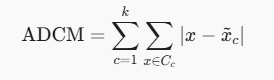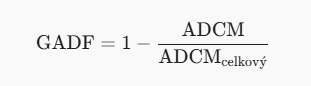

In [6]:
from mapclassify.classifiers import gadf
print(f"ADCM (Absolute Standardized Mean Deviation): {fishman.adcm}")
fishman_dva = mc.FisherJenks(data, k=5)
print(f"ADCM (Absolute Standardized Mean Deviation): {fishman_dva.adcm}") # lepší výsledek
# Jako první argument musíme předat samotná data a jako druhý název metody
gadf_hodnota = mc.gadf(data, method="FisherJenks", maxk = 3)
gadf_hodnota_dva = mc.gadf(data, method="FisherJenks", maxk = 5)
print(f"GADF (Goodness of Absolute Deviation Fit): {gadf_hodnota}")
print(f"GADF (Goodness of Absolute Deviation Fit): {gadf_hodnota_dva}")

ADCM (Absolute Standardized Mean Deviation): 1574.42
ADCM (Absolute Standardized Mean Deviation): 799.24
GADF (Goodness of Absolute Deviation Fit): (3, FisherJenks

     Interval        Count
--------------------------
[   0.13,  192.05] |    52
( 192.05,  722.85] |     5
( 722.85, 4111.45] |     1, np.float64(0.7791809433779668))
GADF (Goodness of Absolute Deviation Fit): (4, FisherJenks

     Interval        Count
--------------------------
[   0.13,  110.74] |    50
( 110.74,  370.50] |     6
( 370.50,  722.85] |     1
( 722.85, 4111.45] |     1, np.float64(0.8481032719908105))


5. SPOJENÉ KLASIFIKÁTORY

`Pooled` klasifikátor spočítá jednotné hranice intervalů pro více číselných řad najednou (to je vhodné třeba pro srovnávání stejných dat z více časových období).

In [7]:
df = pd.DataFrame({
    'rok_2010': [12.5, 9.8, 14.1],
    'rok_2011': [7.6, 1.1, 14.9],
    'rok_2012': [11.11, 11.11, 12.12],
    'rok_2013': [8.2,  6.1, 10.0],
    'rok_2014': [4.1,  3.0,  5.5]
})

pooled_fishman = mc.Pooled(df.values, classifier='FisherJenks', k=3)

#společné hranice pro všechny roky:
print(pooled_fishman.global_classifier.bins)
#klasifikace konkrétního roku s "pooled" hranicemi
print(pooled_fishman.col_classifiers[0].yb)


[ 6.1  11.11 14.9 ]
[2 1 2]


# **VZTAH MAPCLASSIFY A GEOPANDAS**

Prostřednictvím parametru `scheme` v metodě `.plot()` umí GeoPandas využít algoritmy z MapClassify a implementovat ho rovnou do mapy.

**DATA**

Pro tuto část si stáhneme data ze stránky [ARCDATA PRAHA](https://data.arcdata.cz) a to vrstvu krajů ČR a vrstvu obcí. (*Data ArcČR © ČÚZK, ČSÚ, ARCDATA PRAHA 2024.*)

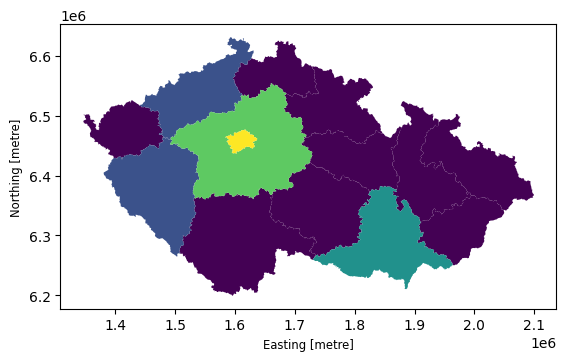

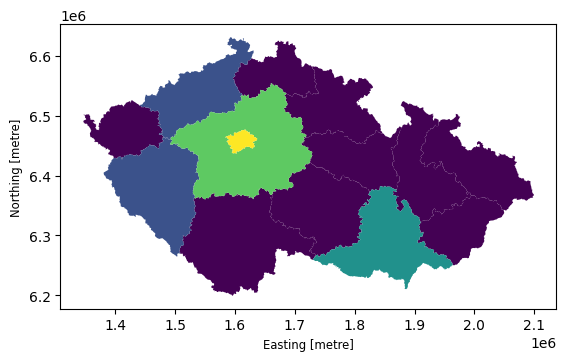

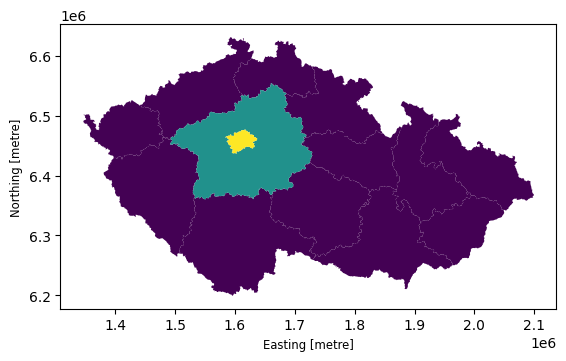

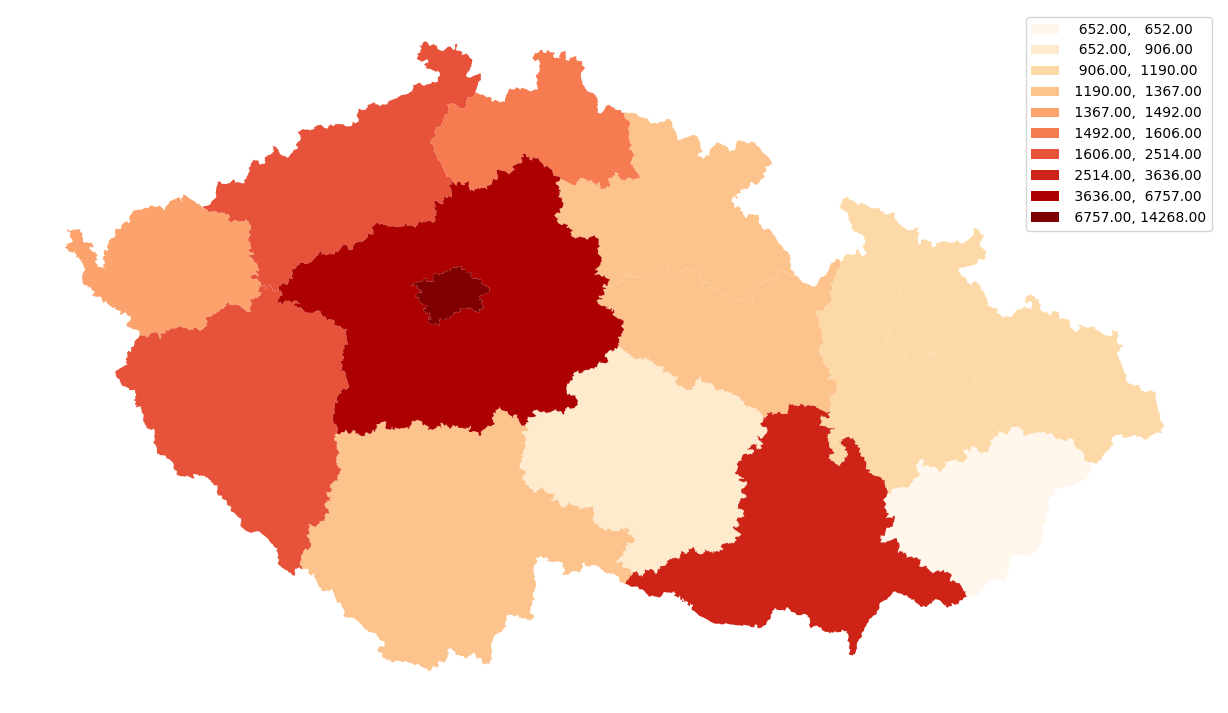

In [8]:
kraje = gpd.read_file('Kraje.shp')
#print(list(kraje.columns))
kraje.plot(column='pravoslavn', scheme='FisherJenks', k=5)
kraje.plot(column='pravoslavn', scheme='NaturalBreaks', k=5)
kraje.plot(column='pravoslavn', scheme='PrettyBreaks', k=5)

#tvorba "lepší" mapy
ax = kraje.plot(
    figsize=(16, 9),      #určení velikosti zobrazení
    column="pravoslavn",  #sloupec ze kterého bereme hodnoty
    scheme="FisherJenks", #volba algoritmu pro tvorbu tříd
    k=10,                 #počet tříd
    cmap="OrRd",          #určení barevné palety
    legend=True,          #tvorba legendy
)
ax.set_axis_off()

Další způsob jak použít vlastnosti knihovny mapclassify, bez nutnosti jejího importu, je volat jí rovnou z "*mateřského*" balíčku PySal.

In [9]:
fishman_pysal = psmc.NaturalBreaks(data, k=10)
print(fishman_pysal)

NaturalBreaks

     Interval        Count
--------------------------
[   0.13,   16.70] |    37
(  16.70,   40.48] |     7
(  40.48,   75.29] |     5
(  75.29,  110.74] |     1
( 110.74,  192.05] |     2
( 192.05,  264.93] |     1
( 264.93,  329.92] |     2
( 329.92,  370.50] |     1
( 370.50,  722.85] |     1
( 722.85, 4111.45] |     1


**NENASYTNÝ MAPCLASSIFY**

Funkce greedy slouží k topologickému obarvování map. Jejím hlavním úkolem je přiřadit každému polygonu barvu tak, aby žádné dva sousedící polygony neměly stejnou barvu.

Využívá k tomu tzv. "hladový" algoritmus. Ten postupně prochází jednotlivé geometrie a každé z nich přiřadí první dostupnou barvu, která ještě nebyla použita u žádného jiného souseda.

Tato funkce je vhodná v případě, že potřebujeme vytvořit mapu, kde je třeba od sebe jasně odlišit sousední oblasti.

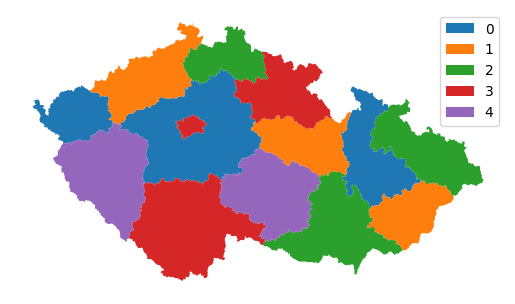

In [10]:
#vytvoření nového sloupce kde každý kraj dostane pomocí greedy algoritmu id barvy
kraje['barva_id'] = mc.greedy(kraje)
k_plot = kraje.plot(column="barva_id", categorical=True, legend=True)
k_plot.set_axis_off()

*tip: v greedy můžeme nastavovat strategie vybarvování*

**ALTERNATIVA MAPCLASSIFY**

Pokud z nějakého důvodu potřebujeme použít pro rozdělení dat jiný balíček než `mapclassify`, naší nejlepší možností by mohl být balíček `jenkspy`. Tento balíček je ale omezen pouze na "Jenksové" přirozené zlomy (Fisher-Jenks a Natural Breaks). Dále knihovny `pandas`, `scikit-learn`, `numpy`. Všechny tyto balíčky mají méně algoritmů řazení dat, neumí měřit přesnosti zařazení dat (ADCM) a nemají tak silnou vazbu k balíčku `geopandas` (parametr `scheme=`)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 638.1/638.1 kB 7.3 MB/s  0:00:00
[np.int64(0), np.int64(2264), np.int64(7889), np.int64(17563), np.int64(35890), np.int64(68153), np.int64(106063), np.int64(174007), np.int64(282450), np.int64(398510), np.int64(1301432)]
FisherJenks

        Interval           Count
--------------------------------
[      0.00,    2264.00] |  5652
(   2264.00,    7889.00] |   447
(   7889.00,   17563.00] |    91
(  17563.00,   35890.00] |    42
(  35890.00,   68153.00] |    15
(  68153.00,  106063.00] |     7
( 106063.00,  174007.00] |     1
( 174007.00,  282450.00] |     1
( 282450.00,  398510.00] |     1
( 398510.00, 1301432.00] |     1


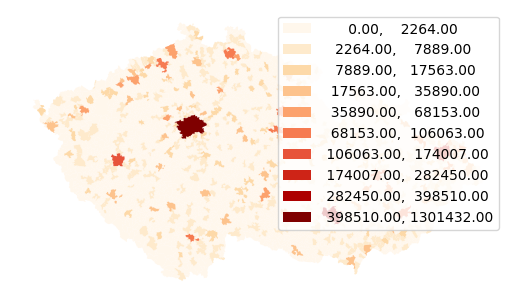

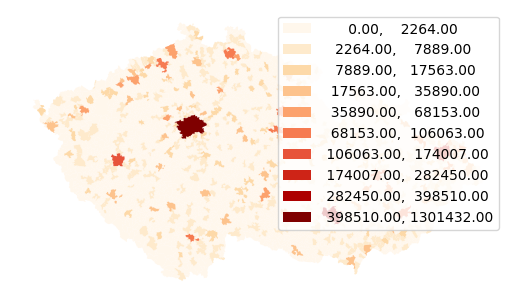

In [13]:
!pip install jenkspy
import jenkspy

obce = gpd.read_file('Obce.shp')

fish_jenks = jenkspy.jenks_breaks(obce['Poc_obyv_S'], n_classes=10)
print(fish_jenks)
fishman = mc.FisherJenks(obce['Poc_obyv_S'], k=10)
print(fishman)

fishjenks_plot = obce.plot(
    column="Poc_obyv_S",  #sloupec ze kterého bereme hodnoty
    scheme="UserDefined", #volba algoritmu pro tvorbu tříd
    classification_kwds={"bins": fish_jenks[1:]},
    cmap="OrRd",          #určení barevné palety
    legend=True,          #tvorba legendy
)
fishjenks_plot.set_axis_off()

fishman_plot = obce.plot(
    column="Poc_obyv_S",  #sloupec ze kterého bereme hodnoty
    scheme="FisherJenks", #volba algoritmu pro tvorbu tříd
    k=10,
    cmap="OrRd",          #určení barevné palety
    legend=True,          #tvorba legendy
)
fishman_plot.set_axis_off()

# PŘÍKLAD VYUŽITÍ

**Úloha:** Zmapuj počet žen v jednotlivých obcích ČR a zjisti, jak se jejich prostorové rozmístění liší mezi kraji s různou věkovou strukturou obyvatelstva.

['kod', 'nazev', 'regionsoud', 'nutslau', 'datumvznik', 'Poc_obyv_1', 'Poc_obyv_2', 'Poc_obyv_3', 'Poc_obyv_4', 'Poc_obyv_m', 'Poc_obyv_z', 'Poc_obyv_0', 'Poc_obyv_5', 'Poc_obyv_6', 'Poc_obyv_7', 'Poc_obyv_8', 'Poc_obyv_9', 'Poc_obyv_n', 'Poc_oby_10', 'Poc_oby_11', 'Prumerny_v', 'Prumerny_1', 'Prumerny_2', 'muzi_svobo', 'muzi_zenat', 'muzi_rozve', 'muzi_ovdov', 'zeny_svobo', 'zeny_vdane', 'zeny_rozve', 'zeny_ovdov', 'pocet_obyv', 'bez_vzdela', 'zakl_vzdel', 'stredni_vz', 'stredni__1', 'vyssi_odbo', 'vysokoskol', 'vzdelani_n', 'ceska_naro', 'moravska_n', 'slezska_na', 'slovenska_', 'ukrajinska', 'vietnamska', 'ostatní_n', 'poc_obyv_S', 'bez_naboze', 'cirkev_ces', 'cirkev_rim', 'ceskobratr', 'katolicka_', 'krestanstv', 'svedkove_j', 'vira_neuve', 'verici_hla', 'verici_neh', 'pravoslavn', 'protestant', 'ostatni_vi', 'celkem_dom', 'vlastnik_d', 'vlastnik_1', 'vlastnik_2', 'vlastnik_3', 'vlastnik_4', 'vlastnik_5', 'spoluvlast', 'vystavba_p', 'vystavba_1', 'vystavba_2', 'vystavba_3', 'vystav

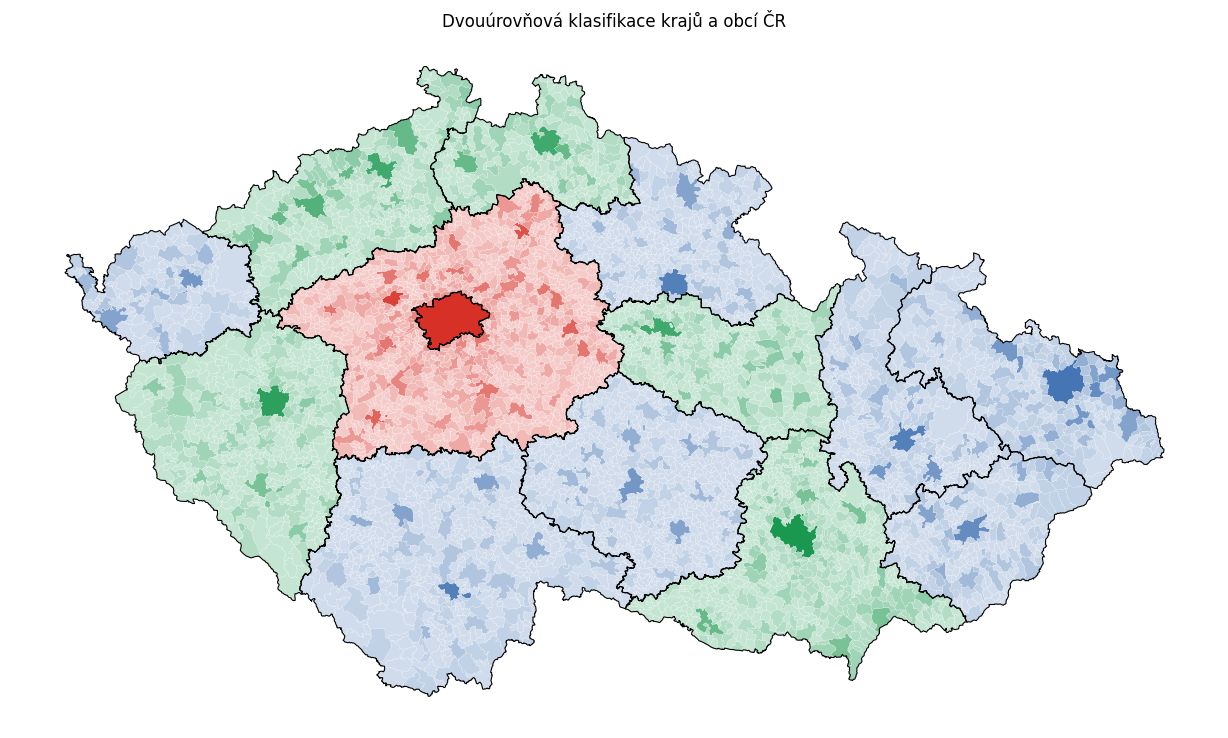

In [21]:
import geopandas as gpd
import mapclassify as mc
import numpy as np

obce = gpd.read_file('Obce.shp')
kraje = gpd.read_file('Kraje.shp')
print(list(kraje))
print(list(obce))
#klasifikace krajů
klas_kraje = mc.NaturalBreaks(kraje["Prumerny_v"], k = 3)
#uložení čísla třídy
kraje["trida_kraje"] = klas_kraje.yb
#prirazeni klasifikacni tridy obcím
obce["trida_kraje"] = obce["vusc"].map(kraje.set_index("kod")["trida_kraje"])

#vytvoření sloupců pro třídu a barvu
obce["trida_obce"] = np.nan
obce["barva"] = "#dddddd"

#výběr základních barev
barvy = np.array([
    [215, 48, 39],
    [26, 152, 80],
    [69, 117, 180]
])

#nastavení intenzity odstínů barev
odstiny = np.linspace(0.25, 1, 10)

for trida in range(3):
  #výběr obcí patřících do krajů stejné klasifikační třídy
  vyber = obce["trida_kraje"] == trida
  #klasifikace ve vybraných obcích
  klas_obce = mc.NaturalBreaks(obce.loc[vyber, "poc_zen"], k=10)
  #uložení tříd
  obce.loc[vyber, "trida_obce"] = klas_obce.yb
  #výběr barvy
  barva = barvy[trida]
  #přiřazení barvy
  for trida_obce in range(10):
    #výpočet odstínu
    odstin = (barva * odstiny[trida_obce] + 255 * (1 - odstiny[trida_obce])).astype(int)
    #převod barev na hex
    hex_barva = "#{:02x}{:02x}{:02x}".format(*odstin)
    #přiřazení barvy obcím
    obce.loc[vyber & (obce["trida_obce"] == trida_obce), "barva"] = hex_barva
  #print(f"Třída krajů {trida + 1}: {klas_obce.bins}")

ax = obce.plot(
    color=obce["barva"],
    figsize=(16, 9),
    edgecolor="white",
    linewidth=0.1,
    legend=True
)

kraje.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

ax.set_title("Dvouúrovňová klasifikace krajů a obcí ČR")

ax.set_axis_off()


**ZDROJE**

DATA: Data ArcČR © ČÚZK, ČSÚ, ARCDATA PRAHA 2024.

Zdroj informací: [PySAL: mapclassify v2.11.0 Manual](https://pysal.org/mapclassify/)

Pomocník: CHAT GPT